In [ ]:
# @title
!pip install normflows

In [ ]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import numpy as np

import normflows as nf
import torch
from torch.utils.data import TensorDataset, DataLoader
from jax import grad, jit, vmap, random, lax
from tqdm import tqdm, trange
from tqdm.auto import trange
from functools import partial
seed = 0
key = random.PRNGKey(seed)

In [ ]:
#calculate U(x) = -log p(x), disregard Z normalization term because we
# will only use this function by taking it's gradient
def get_U(x):
    x1 = x[0]
    x2 = x[1]

    r = jnp.sqrt(x1**2 + x2**2 + 1e-6)

    theta = jnp.arctan2(x2, x1)
    log_p = jnp.log((2 + jnp.cos(7 * theta)) *
                      (r**2) *
                      jnp.exp(-((r - 5)**2) /  2)
                      )
    U_x = -log_p
    return U_x

  0%|          | 0/20000 [00:00<?, ?it/s]

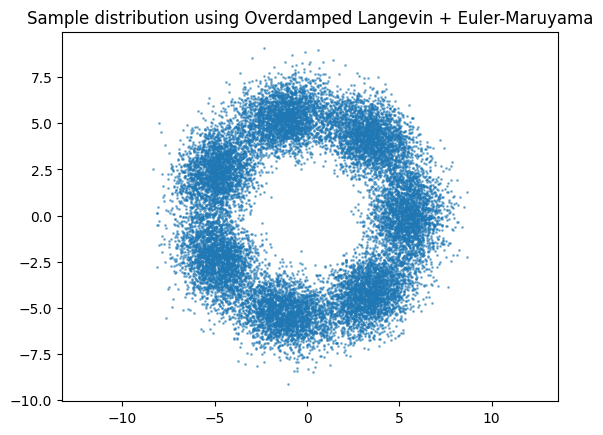

In [ ]:
#Run a step of euler-maruyama with step size h
@jit
def euler_maruyama_step(h, x, key):
    #generate new random Z_n at every step
    Z_n = random.normal(key, x.shape)

    #calculate the grad U(x) at the current time step, use vmap
    #to map the gradient over argument axes
    grad_U = vmap(grad(get_U))(x)

    #run euler-maruyama step
    x_next = x - h*grad_U + jnp.sqrt(2*h) * Z_n
    return x_next

#run sampling process on overdampd langevin dynamics via
#euler-maruyama with num_steps steps, step size h, initialize
#x to N(0, I)
def overdamped_langevin_sampling(num_steps, h, x_initial, key):
    x_curr = x_initial
    for _ in trange(num_steps):
        key, subkey = jax.random.split(key)
        x_curr = euler_maruyama_step(h, x_curr, subkey)
    return x_curr

#Hyperparameter setup, initialize x as instructed
num_steps = 20000
num_samples = 20000
h = 1e-3

x_initial = random.normal(key, (num_samples, 2))

#Run sampling and plot results
final_samples = overdamped_langevin_sampling(num_steps, h, x_initial, key)
plt.figure()
plt.scatter(final_samples[:, 0], final_samples[:, 1], s=1, alpha=0.5)
plt.title("Sample distribution using Overdamped Langevin + Euler-Maruyama")
plt.axis('equal')
plt.show()

  0%|          | 0/20000 [00:00<?, ?it/s]

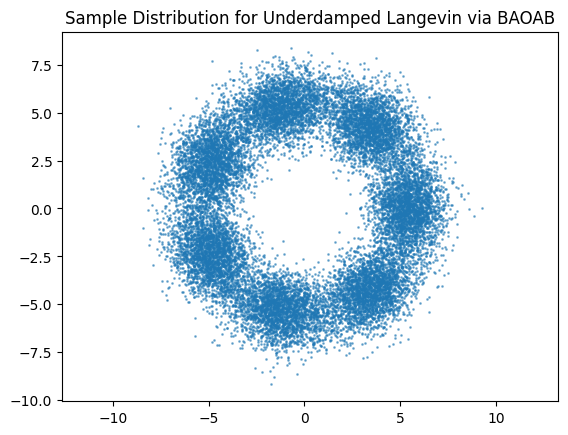

In [ ]:
#Run BAOAB step
@jit
def BAOAB_step(h, x, v, key):

    v_curr = run_B(x, v, h)
    x_curr = run_A(x, v_curr, h)
    v_curr = run_O(v_curr, h, key)
    x_curr = run_A(x_curr, v_curr, h)
    v_curr = run_B(x_curr, v_curr, h)

    return x_curr, v_curr

#define each of B, A, and O
@jit
def run_B(x, v, h):
    grad_U = vmap(grad(get_U))(x)
    return v - (h/2)*grad_U

@jit
def run_A(x, v, h):
    return x + (h/2)*v

@jit
def run_O(v, h, key):
    z = random.normal(key, v.shape)
    return jnp.exp(-h) * v + (jnp.sqrt(1 - jnp.exp(-2*h))* z)

#Run entire sampling process
def underdamped_langevin_sampling(num_steps, h, x_initial, v_initial, key):
    x_curr = x_initial
    v_curr = v_initial
    for _ in trange(num_steps):
        key, subkey = jax.random.split(key)
        x_curr, v_curr = BAOAB_step(h, x_curr, v_curr, subkey)
    return x_curr

#Define hyperparameters, randomly initialize position/velocity
num_steps = 20000
num_samples = 20000
h = 1e-3
key, subkey = jax.random.split(key)
x_initial = random.normal(subkey, (num_samples, 2))
v_initial = random.normal(subkey, (num_samples, 2))

final_samples = underdamped_langevin_sampling(num_steps, h, x_initial, v_initial, key)

plt.figure()
plt.scatter(final_samples[:, 0], final_samples[:, 1], s=1, alpha=0.5)
plt.title("Sample Distribution for Underdamped Langevin via BAOAB")
plt.axis('equal')
plt.show()

  0%|          | 0/20000 [00:00<?, ?it/s]

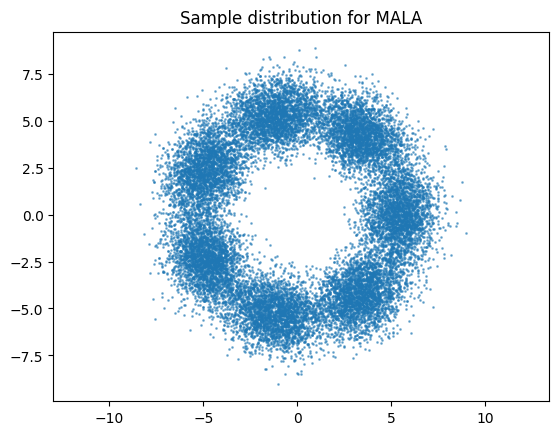

In [ ]:
#define a function to easily be able to get batched U(x)
batch_U = vmap(get_U)
grad_U = vmap(grad(get_U))

#calculate log of the transition probability,
#given previous state x_from, proposal state x_from
#and grad U(proposed state)
@jit
def log_transition(x_to, x_from, grad_from, h):
    mu = x_from - h * grad_from
    return ((-1.0/(4.0*h)) * jnp.sum((x_to - mu)**2, axis=1))

#Run a single step of metropolis-adjusted langevin
@jit
def MALA_step(h, x, key):
    x_curr = x

    #run Euler-Maruyama to generate proposal x_propose
    Z_n = random.normal(key, x_curr.shape)
    grad_U_x_curr = grad_U(x_curr)
    x_propose = x_curr - h*grad_U_x_curr + jnp.sqrt(2*h) * Z_n

    #compute grad U(x_propose)
    grad_U_x_propose = grad_U(x_propose)

    #Compute logs to facilitate calculate of log acceptance prob
    log_p_x_propose = batch_U(x_propose)
    log_p_x_curr = batch_U(x_curr)

    #compute log of transition prob from curr to propose and vice versa
    log_trans_1 = log_transition(x_curr, x_propose, grad_U_x_propose, h)
    log_trans_2 = log_transition(x_propose, x_curr, grad_U_x_curr, h)

    #compute log of acceptance probability (avoids divide by 0)
    log_prob = (log_p_x_propose - log_p_x_curr) + (log_trans_2 - log_trans_1)
    #probability shouldn't be below 0
    log_prob = jnp.minimum(0.0, log_prob)
    key, subkey = jax.random.split(key)

    #generate random u to choose if we move to proposal or not based on log_prob
    u = random.uniform(subkey, shape = (x_curr.shape[0],))
    accept = jnp.log(u) < log_prob
    x_curr = jnp.where(accept[:, None], x_propose, x_curr)
    return x_curr, jnp.mean(accept)

#Run entire MALA algorithm
def run_MALA(num_steps, h, x_initial, key):
    x_curr = x_initial
    acceptances = []
    for _ in trange(num_steps):
        key, subkey = jax.random.split(key)
        x_curr,accept = MALA_step(h, x_curr, subkey)
        acceptances.append(accept)
    acceptances = jnp.array(acceptances)
    accept_rate = jnp.mean(acceptances)
    return x_curr, accept_rate


num_steps = 20000
num_samples = 20000
h = 1e-3
key, subkey = jax.random.split(key)
x_initial = random.normal(subkey, (num_samples, 2))

final_samples, accept = run_MALA(num_steps, h, x_initial, key)

plt.figure()
plt.scatter(final_samples[:, 0], final_samples[:, 1], s=1, alpha=0.5)
plt.title("Sample distribution for MALA")
plt.axis('equal')
plt.show()

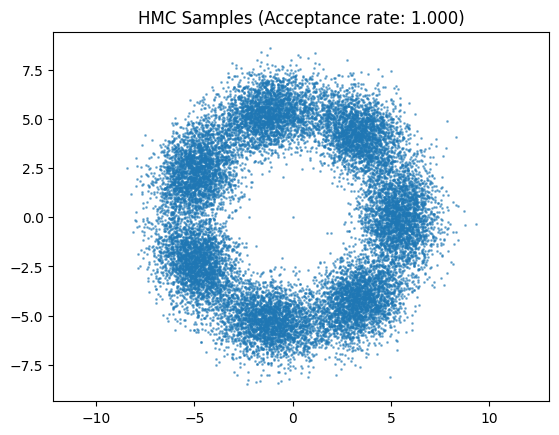

In [ ]:
# Stormer-Verlet with lax.scan
def leapfrog_step(carry, _):
    x, w, h = carry
    k1 = -grad_U(x)
    w_half = w + 0.5 * h * k1
    x_new = x + h * w_half
    k2 = -grad_U(x_new)
    w_new = w_half + 0.5 * h * k2
    return (x_new, w_new, h), None


def stormer_verlet_fn(x, w, n, h):
    (x_final, w_final, _), _ = lax.scan(leapfrog_step, (x, w, h), None, length=n)
    return x_final, w_final

stormer_verlet = partial(jit, static_argnums=(2,))(stormer_verlet_fn)

# Run a single HMC step
@partial(jit, static_argnums=(3,))
def hmc_step(x_curr, key, h, n):
    key, subkey = random.split(key)
    w_curr = random.normal(subkey, x_curr.shape)

    H_curr = 0.5 * jnp.sum(w_curr**2, axis=1) + batch_U(x_curr)

    # Calculate proposal
    x_propose, w_propose = stormer_verlet(x_curr, w_curr, n, h)

    # Proposed Hamiltonian
    H_propose = 0.5 * jnp.sum(w_propose**2, axis=1) + batch_U(x_propose)

    log_accept_prob = jnp.minimum(0.0, H_curr - H_propose)

    # Accept/reject
    key, subkey = random.split(key)
    u = random.uniform(subkey, shape=(x_curr.shape[0],))
    accept = jnp.log(u) < log_accept_prob
    x_new = jnp.where(accept[:, None], x_propose, x_curr)

    return x_new, jnp.mean(accept), key


# Run full HMC algorithm with lax.scan
def HMC(num_steps, h, x_initial, key, n, burn_in=0.2):
    def hmc_body(carry, _):
        x_curr, key = carry
        x_new, accept, key = hmc_step(x_curr, key, h, n)
        return (x_new, key), accept

    (x_final, _), acceptances = lax.scan(hmc_body, (x_initial, key), None, length=num_steps)

    # Discard burn-in
    burn_idx = int(num_steps * burn_in)
    acceptances = acceptances[burn_idx:]
    accept_rate = jnp.mean(acceptances)

    return x_final, accept_rate


# Hyperparameters & run
num_steps = 5000
num_samples = 20000
h = 0.05
n = 20

key = random.PRNGKey(0)
key, subkey = random.split(key)
x_initial = random.normal(subkey, (num_samples, 2))

final_samples, accept_rate = HMC(num_steps, h, x_initial, key, n)

#Plot HMC
plt.figure()
plt.scatter(final_samples[:, 0], final_samples[:, 1], s=1, alpha=0.5)
plt.title(f"HMC Samples (Acceptance rate: {accept_rate:.3f})")
plt.axis('equal')
plt.show()

Generating reference (h=1e-4) using Euler-Maruyama...


  0%|          | 0/50000 [00:00<?, ?it/s]

Reference E[r^2] (Transient t=5.0): 31.75778
Testing step sizes


  0%|          | 0/50 [00:00<?, ?it/s]

h=0.1000 | Error=1.02e-01


...

h=0.0125 | Error=1.37e-02


  0%|          | 0/800 [00:00<?, ?it/s]

h=0.0063 | Error=7.35e-03


  0%|          | 0/1600 [00:00<?, ?it/s]

h=0.0031 | Error=5.83e-03


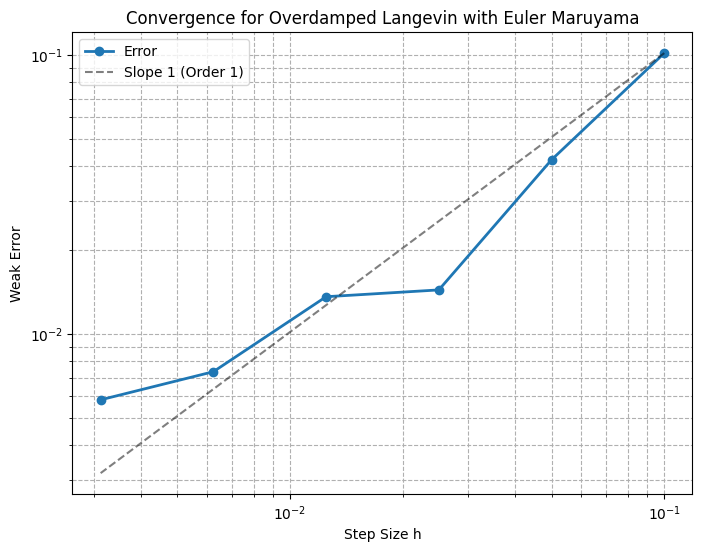

Slope of errors: 0.8081649541854858


In [ ]:
def overdamped_langevin_convergence(key):
    #Set parameters, run until t = 5 for all h values
    T = 5.0
    num_samples = 5_000_000  # High sample count to see the error slope
    h_vals = jnp.array([0.1, 0.05, 0.025, 0.0125, 0.00625, 0.003125])



    # Initialize near (r=5) to avoid long burn-in times
    key, subkey = random.split(key)
    angles = random.uniform(subkey, (num_samples,)) * 2 * jnp.pi
    x_initial = jnp.stack([5.0 * jnp.cos(angles), 5.0 * jnp.sin(angles)], axis=1)

    print("Generating reference (h=1e-4) using Euler-Maruyama...")
    h_ref = 1e-4
    steps_ref = int(T / h_ref)
    key, subkey = random.split(key)
    x_ref = overdamped_langevin_sampling(steps_ref, h_ref, x_initial, subkey)

    # Calculate Reference Value
    ref_val = jnp.mean(jnp.sum(x_ref**2, axis=1))
    print(f"Reference E[r^2] (Transient t=5.0): {ref_val:.5f}")

    #Run loop over h values
    errors = []
    print("Testing step sizes")
    for h in h_vals:
        n_steps = int(T / h)

        key, subkey = random.split(key)
        x_final = overdamped_langevin_sampling(n_steps, h, x_initial, subkey)

        # Calculate Error
        val = jnp.mean(jnp.sum(x_final**2, axis=1))
        error = jnp.abs(val - ref_val)
        errors.append(error)
        print(f"h={h:.4f} | Error={error:.2e}")

    #Plot errors
    errors = jnp.array(errors)
    plt.figure(figsize=(8, 6))
    plt.loglog(h_vals, errors, 'o-', linewidth=2, label='Error')

    # Reference line with slope 1
    slope_1 = errors[0] * (h_vals / h_vals[0])
    plt.loglog(h_vals, slope_1, 'k--', alpha=0.5, label='Slope 1 (Order 1)')
    plt.xlabel('Step Size h')
    plt.ylabel('Weak Error')
    plt.grid(True, which="both", ls="--")
    plt.title('Convergence for Overdamped Langevin with Euler Maruyama')
    plt.legend()
    plt.show()
    m,b = jnp.polyfit(jnp.log(h_vals), jnp.log(errors), 1)
    print(f"Slope of errors: {m}")
key = random.PRNGKey(42)
overdamped_langevin_convergence(key)

Generating BAOAB Reference (h=1e-4)...


  0%|          | 0/50000 [00:00<?, ?it/s]

Reference E[r^2]: 32.09948
Testing step sizes...


  0%|          | 0/5 [00:00<?, ?it/s]

h=1.0000 | Error=2.66e-01


...

h=0.5000 | Error=5.41e-02


  0%|          | 0/20 [00:00<?, ?it/s]

h=0.2500 | Error=1.38e-02


  0%|          | 0/40 [00:00<?, ?it/s]

h=0.1250 | Error=1.11e-02


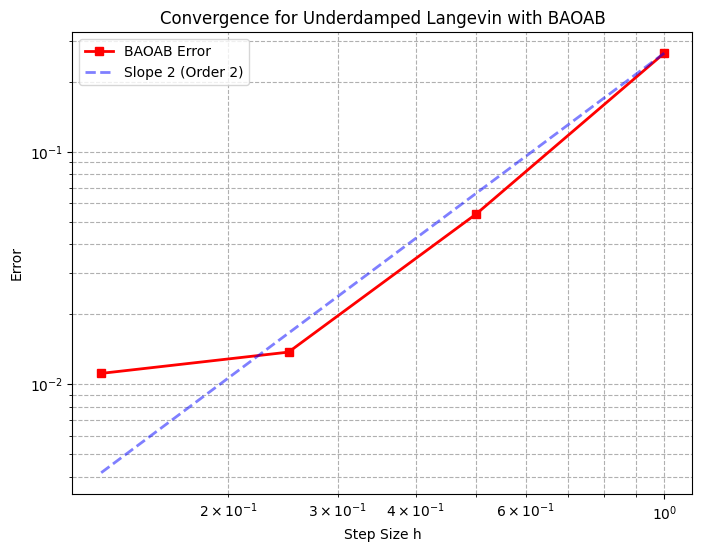

Slope of errors: 1.5703727006912231


In [ ]:
#Test baoab convergence for underdamped langevin
def run_baoab_convergence():
    # Parameters
    T = 5.0
    num_samples = 5_000_000


    # Step sizes
    h_vals = jnp.array([1.0, 0.5, 0.25, 0.125])

    rng_key = random.PRNGKey(42)

    # Initialize x at r=5, v standard normal
    rng_key, k1, k2 = random.split(rng_key, 3)
    angles = random.uniform(k1, (num_samples,)) * 2 * jnp.pi
    x_init = jnp.stack([5.0 * jnp.cos(angles), 5.0 * jnp.sin(angles)], axis=1)
    v_init = random.normal(k2, (num_samples, 2))


    print("Generating BAOAB Reference (h=1e-4)...")
    h_ref = 1e-4
    n_ref = int(T / h_ref)

    rng_key, subkey = random.split(rng_key)
    x_ref = underdamped_langevin_sampling(n_ref, h_ref, x_init, v_init, subkey)
    ref_val = jnp.mean(jnp.sum(x_ref**2, axis=1))
    print(f"Reference E[r^2]: {ref_val:.5f}")


    errors = []
    print("Testing step sizes...")
    for h in h_vals:
        n_steps = int(T / h)
        rng_key, subkey = random.split(rng_key)
        x_final = underdamped_langevin_sampling(n_steps, h, x_init, v_init, subkey)
        val = jnp.mean(jnp.sum(x_final**2, axis=1))
        error = jnp.abs(val - ref_val)
        errors.append(error)
        print(f"h={h:.4f} | Error={error:.2e}")

    #Plot
    errors = jnp.array(errors)
    plt.figure(figsize=(8, 6))
    plt.loglog(h_vals, errors, 's-', linewidth=2, color='red', label='BAOAB Error')

    # Plot Slope 2
    slope_2 = errors[0] * (h_vals / h_vals[0])**2
    plt.loglog(h_vals, slope_2, 'b--', alpha=0.5, linewidth=2, label='Slope 2 (Order 2)')

    plt.xlabel('Step Size h')
    plt.ylabel('Error')
    plt.title('Convergence for Underdamped Langevin with BAOAB')
    plt.grid(True, which="both", ls="--")
    plt.legend()
    plt.show()
    m,b = jnp.polyfit(jnp.log(h_vals), jnp.log(errors), 1)
    print(f"Slope of errors: {m}")

# Run
run_baoab_convergence()

  0%|          | 0/15000 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

h=0.2000 | Acceptance Rate=0.97 | Error =2.40e-02


  0%|          | 0/15 [00:00<?, ?it/s]

h=0.1000 | Acceptance Rate=0.99 | Error =8.04e-02


...

h=0.0250 | Acceptance Rate=1.00 | Error =7.05e-02


  0%|          | 0/120 [00:00<?, ?it/s]

h=0.0125 | Acceptance Rate=1.00 | Error =1.21e-01


  0%|          | 0/300 [00:00<?, ?it/s]

h=0.0050 | Acceptance Rate=1.00 | Error =9.41e-02


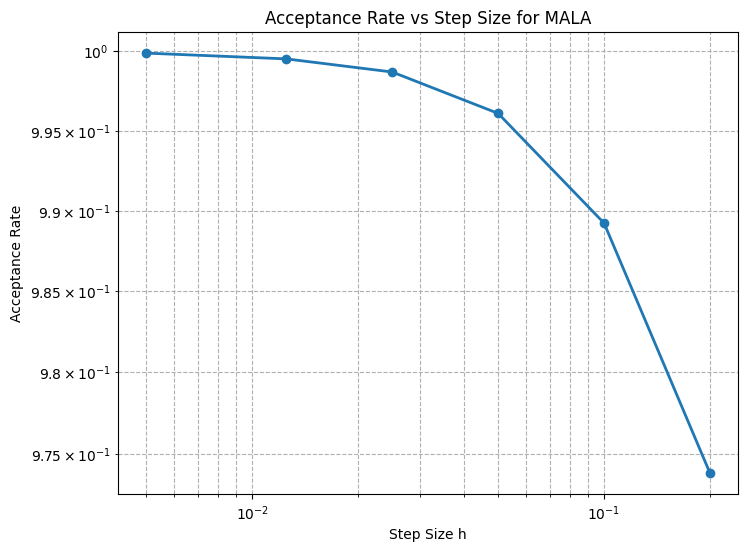

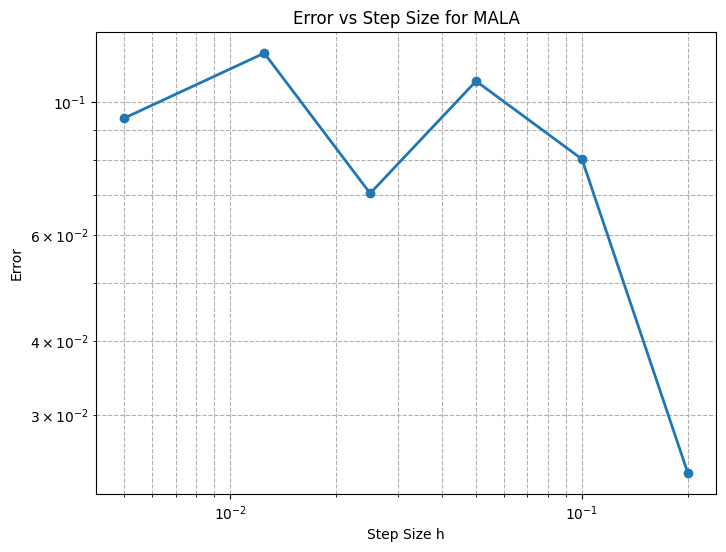

In [ ]:
def MALA_acceptance_rate():
    seed = 0
    key = random.PRNGKey(seed)
    key, subkey = random.split(key)

    # Set parameters
    T = 1.5

    # Step sizes to test (limit h -> 0)
    h_values = jnp.array([0.2, 0.1, 0.05, 0.025, 0.0125, 0.005])
    num_samples = 20_000
    angles = random.uniform(subkey, (num_samples,)) * 2 * jnp.pi
    x_initial = jnp.stack([5.0 * jnp.cos(angles), 5.0 * jnp.sin(angles)], axis=1)
    #Reference solution

    h = 1e-4
    n_steps = int(T / h)
    key, subkey = random.split(key)
    x_ref, _ = run_MALA(n_steps, h, x_initial, subkey)
    ref_val = jnp.mean(jnp.sum(x_ref**2, axis=1))


    accept_rates = []
    errors = []
    for h in h_values:
        n_steps = int(T / h)
        key, subkey = random.split(key)
        x_final, accept_rate = run_MALA(n_steps, h, x_initial, subkey)
        x_val = jnp.mean(jnp.sum(x_final**2, axis=1))
        error = jnp.abs(x_val - ref_val)
        errors.append(error)
        accept_rates.append(accept_rate)

        print(f"h={h:.4f} | Acceptance Rate={accept_rate:.2f} | Error ={error:.2e}")


    # Plot
    plt.figure(figsize=(8, 6))
    plt.loglog(h_values, accept_rates, 'o-', linewidth=2, label='Acceptance Rate')
    plt.xlabel('Step Size h')
    plt.ylabel('Acceptance Rate')
    plt.title('Acceptance Rate vs Step Size for MALA')
    plt.grid(True, which="both", ls="--")


    plt.figure(figsize=(8, 6))
    plt.loglog(h_values, errors, 'o-', linewidth=2, label='Error')
    plt.xlabel('Step Size h')
    plt.ylabel('Error')
    plt.title('Error vs Step Size for MALA')
    plt.grid(True, which="both", ls="--")
    plt.show()

MALA_acceptance_rate()

h=0.5000 | Acceptance Rate=0.97 | Error =2.46e-02
h=0.1000 | Acceptance Rate=1.00 | Error =4.78e-02
h=0.0100 | Acceptance Rate=1.00 | Error =1.49e-01
h=0.0010 | Acceptance Rate=1.00 | Error =4.18e-02


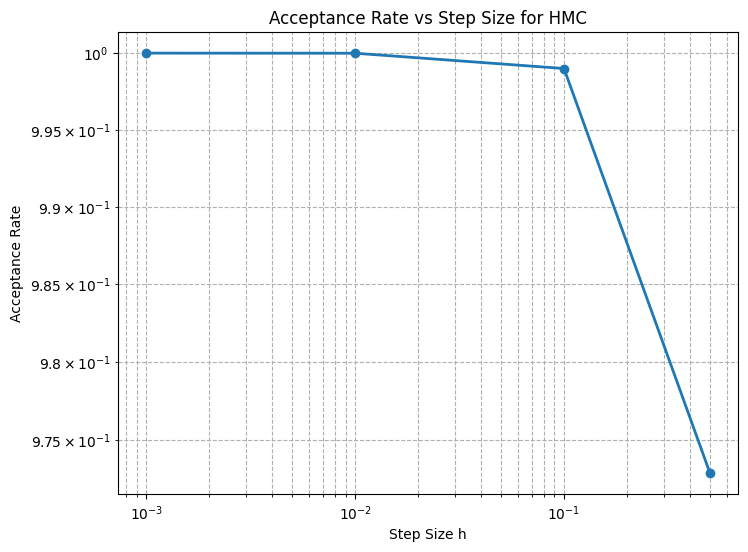

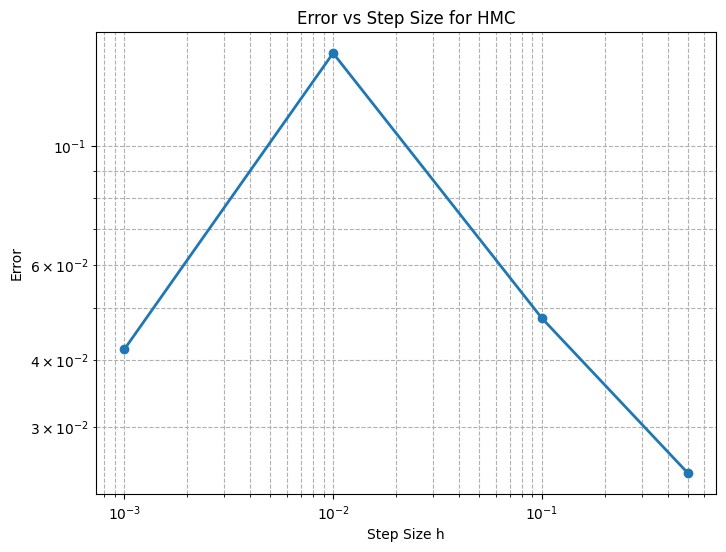

In [ ]:
def HMC_acceptance_rate():
    seed = 0
    key = random.PRNGKey(seed)
    key, subkey = random.split(key)

    # Set parameters
    T = 1.5

    # Step sizes to test (limit h -> 0)
    h_values = jnp.array([0.5, 0.1, 0.01, 0.001])
    num_samples = 20_000
    num_steps = 100
    angles = random.uniform(subkey, (num_samples,)) * 2 * jnp.pi
    x_initial = jnp.stack([5.0 * jnp.cos(angles), 5.0 * jnp.sin(angles)], axis=1)
    #Reference solution

    h = 1e-4
    L_steps = int(T / h)
    key, subkey = random.split(key)
    x_ref, _ = HMC(num_steps, h, x_initial, subkey, L_steps)
    ref_val = jnp.mean(jnp.sum(x_ref**2, axis=1))


    accept_rates = []
    errors = []
    for h in h_values:
        L_steps = int(T / h)
        key, subkey = random.split(key)
        x_final, accept_rate = HMC(num_steps, h, x_initial, subkey, L_steps)
        x_val = jnp.mean(jnp.sum(x_final**2, axis=1))
        error = jnp.abs(x_val - ref_val)
        errors.append(error)
        accept_rates.append(accept_rate)

        print(f"h={h:.4f} | Acceptance Rate={accept_rate:.2f} | Error ={error:.2e}")


    # Plot
    plt.figure(figsize=(8, 6))
    plt.loglog(h_values, accept_rates, 'o-', linewidth=2, label='Acceptance Rate')
    plt.xlabel('Step Size h')
    plt.ylabel('Acceptance Rate')
    plt.title('Acceptance Rate vs Step Size for HMC')
    plt.grid(True, which="both", ls="--")


    plt.figure(figsize=(8, 6))
    plt.loglog(h_values, errors, 'o-', linewidth=2, label='Error')
    plt.xlabel('Step Size h')
    plt.ylabel('Error')
    plt.title('Error vs Step Size for HMC')
    plt.grid(True, which="both", ls="--")
    plt.show()

HMC_acceptance_rate()

In [ ]:
#Now use the samples we have generated to build a normalizing flow model
#Implementation based on this notebook: https://colab.research.google.com/github/VincentStimper/normalizing-flows/blob/master/examples/real_nvp_colab.ipynb

# Define 2D Gaussian base distribution
base = nf.distributions.base.DiagGaussian(2)

# Define list of flows
num_layers = 16
flows = []
for i in range(num_layers):
    # Neural network with two hidden layers having 64 units each
    # Last layer is initialized by zeros making training more stable
    param_map = nf.nets.MLP([1, 64, 64, 2], init_zeros=True)
    # Add flow layer
    flows.append(nf.flows.AffineCouplingBlock(param_map))
    # Swap dimensions
    flows.append(nf.flows.Permute(2, mode='swap'))

# Construct flow model
model = nf.NormalizingFlow(base, flows)

In [ ]:
# Move model on GPU if available
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
model = model.to(device)

100%|██████████| 4000/4000 [02:14<00:00, 29.66it/s]


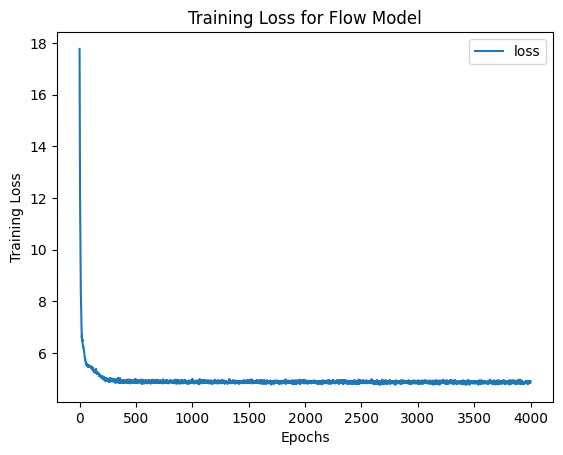

In [ ]:
# Train model
max_iter = 4000
batch_size = 2 ** 9

loss_hist = np.array([])

optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-5)
#generate full training data
total_samples = 50_000
key, subkey = jax.random.split(key)
x_initial = random.normal(subkey, (total_samples, 2))

samples, _ = HMC(10_000, 1e-2, x_initial, subkey, 20)
np_samples = np.asarray(samples)
torch_samples = torch.from_numpy(np_samples)
X = torch_samples.to(device)

dataset = TensorDataset(X)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

for it in tqdm(range(max_iter)):
    optimizer.zero_grad()
    batch = next(iter(dataloader))
    x = batch[0]


    # Compute loss
    loss = model.forward_kld(x)

    # Do backprop and optimizer step
    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()

    # Log loss
    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

# Plot loss
plt.figure()
plt.ylabel("Training Loss")
plt.xlabel("Epochs")
plt.title("Training Loss for Flow Model")
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

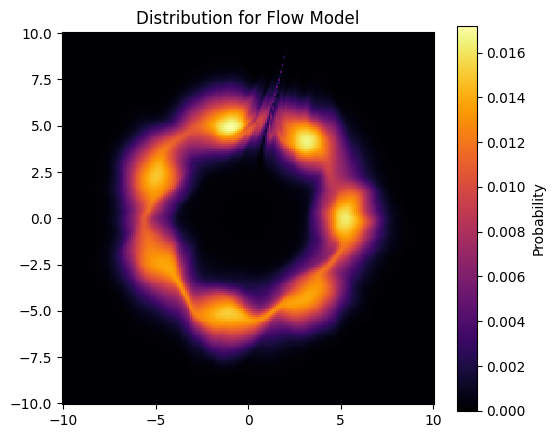

In [ ]:
grid_size = 200
xx, yy = torch.meshgrid(torch.linspace(-10, 10, grid_size), torch.linspace(-10, 10, grid_size))
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.to(device)


# Plot learned distribution
model.eval()
fig, ax = plt.subplots(figsize=(6, 5))

log_prob = model.log_prob(zz).to('cpu').view(*xx.shape)
model.train()
prob = torch.exp(log_prob)
prob[torch.isnan(prob)] = 0
mesh = ax.pcolormesh(xx, yy, prob.data.numpy(), cmap='inferno')
plt.colorbar(mesh, label='Probability')
ax.set_title("Distribution for Flow Model")
ax.set_aspect('equal')

plt.show()